In [2]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

In [3]:
pip install sqlalchemy pymysql

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import urllib.parse
from sqlalchemy import create_engine, text

username = "root"
raw_password = "nrvv@0174"  # Contains the @ symbol
host = "localhost"
port = "3306"
database = "coldiq"

safe_password = urllib.parse.quote_plus(raw_password)
connection_url = f"mysql+pymysql://{username}:{safe_password}@{host}:{port}/{database}"
engine = create_engine(connection_url)


In [5]:
query = """
SELECT *
FROM ml_monthly_prices_fixed
"""

df = pd.read_sql(query, engine)

print(df.shape)

(224758, 19)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 224758 entries, 0 to 224757
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Commodity            224758 non-null  str    
 1   Commodity_ID         224758 non-null  int64  
 2   Variety              224758 non-null  str    
 3   State                224758 non-null  str    
 4   District             224758 non-null  str    
 5   Month_Date           224758 non-null  str    
 6   Price_Year           224758 non-null  int64  
 7   Price_Month          224758 non-null  int64  
 8   Median_Price_Per_MT  224758 non-null  float64
 9   Monthly_Min_Price    224758 non-null  float64
 10  Monthly_Max_Price    224758 non-null  float64
 11  Monthly_Price_Std    217799 non-null  float64
 12  Price_Record_Count   224758 non-null  int64  
 13  Market_Count         224758 non-null  int64  
 14  Price_Lag_1          203820 non-null  float64
 15  Price_Lag_2          186704 

In [7]:
df.isna().sum()

Commodity                  0
Commodity_ID               0
Variety                    0
State                      0
District                   0
Month_Date                 0
Price_Year                 0
Price_Month                0
Median_Price_Per_MT        0
Monthly_Min_Price          0
Monthly_Max_Price          0
Monthly_Price_Std       6959
Price_Record_Count         0
Market_Count               0
Price_Lag_1            20938
Price_Lag_2            38054
Price_Lag_3            52368
Price_Lag_4            64327
Next_Month_Price           0
dtype: int64

In [8]:
df["Next_Month_Price"].describe()

count    224758.000000
mean       3743.103867
std        4039.774602
min         292.000000
25%        1500.000000
50%        2500.000000
75%        4500.000000
max      240040.000000
Name: Next_Month_Price, dtype: float64

In [9]:
features = [
    "Median_Price_Per_MT",
    "Monthly_Min_Price",
    "Monthly_Max_Price",
    "Monthly_Price_Std",
    "Price_Record_Count",
    "Market_Count",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_4",
    "Price_Month"
]

target = "Next_Month_Price"

In [10]:
model_df = df.dropna(
    subset=features + [target]
).copy()

print(model_df.shape)

(158606, 19)


In [11]:
model_df = model_df.sort_values("Month_Date").reset_index(drop=True)

split_date = "2025-07-01"

train_df = model_df[
    model_df["Month_Date"] < split_date
]

test_df = model_df[
    model_df["Month_Date"] >= split_date
]

print("Train:", train_df.shape)
print("Test :", test_df.shape)

Train: (120944, 19)
Test : (37662, 19)


In [12]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(120944, 11) (120944,)
(37662, 11) (37662,)


In [13]:
baseline_predictions = test_df["Median_Price_Per_MT"]

baseline_mae = mean_absolute_error(y_test,baseline_predictions)

baseline_rmse = np.sqrt(mean_squared_error(y_test,baseline_predictions))

baseline_r2 = r2_score(y_test,baseline_predictions)

print("Baseline MAE :", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R²  :", baseline_r2)

Baseline MAE : 590.0960911528862
Baseline RMSE: 1149.699735716894
Baseline R²  : 0.9027194284603602


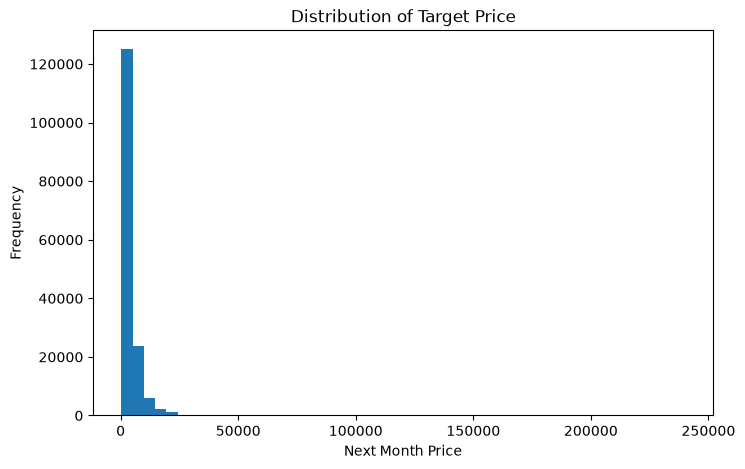

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(model_df["Next_Month_Price"], bins=50)
plt.xlabel("Next Month Price")
plt.ylabel("Frequency")
plt.title("Distribution of Target Price")
plt.show()

In [15]:
target_by_commodity = (
    model_df
    .groupby("Commodity")["Next_Month_Price"]
    .agg(["count", "min", "median", "mean", "max"])
    .sort_values("median")
)

target_by_commodity

model_df.groupby("Commodity")["Next_Month_Price"].median().sort_values()

Commodity
Potato         1400.00
Cabbage        1500.00
Onion          1900.00
Cucumber       2000.00
Tomato         2000.00
Cauliflower    2050.00
Papaya         2703.75
Carrot         2707.50
Chilli         3490.00
Guava          4000.00
Pineapples     4300.00
Peas           4710.00
Mango          5000.00
Orange         6000.00
Grapes         7500.00
Pomegranate    7500.00
Garlic         7550.00
Apples         7950.00
Name: Next_Month_Price, dtype: float64

<Figure size 1200x600 with 0 Axes>

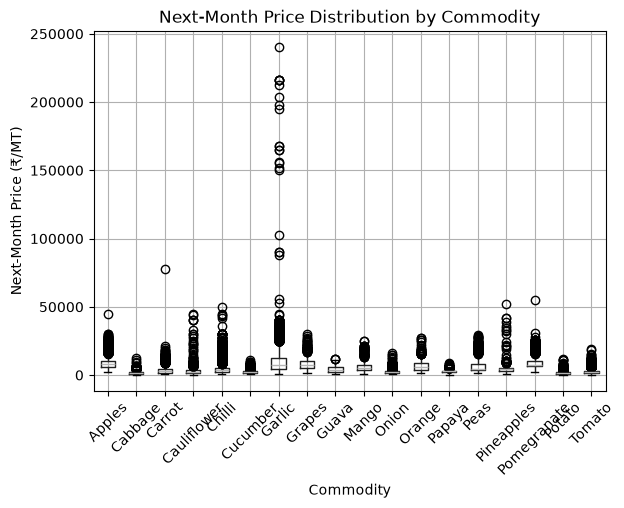

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

model_df.boxplot(
    column="Next_Month_Price",
    by="Commodity",
    rot=45
)

plt.title("Next-Month Price Distribution by Commodity")
plt.suptitle("")
plt.xlabel("Commodity")
plt.ylabel("Next-Month Price (₹/MT)")
plt.show()

In [17]:
model_a_features = [
    "Median_Price_Per_MT",
    "Monthly_Min_Price",
    "Monthly_Max_Price",
    "Monthly_Price_Std",
    "Price_Record_Count",
    "Market_Count",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_4",
    "Price_Month"
]

X_train_a = train_df[model_a_features]
y_train_a = train_df["Next_Month_Price"]

X_test_a = test_df[model_a_features]
y_test_a = test_df["Next_Month_Price"]

In [18]:
linear_model_a = LinearRegression()

linear_model_a.fit(
    X_train_a,
    y_train_a
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](11,)","[ 0.7 , 0.22, 0.14,..., 0.02, 0.03,-10.73]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](11,)","['Median_Price_Per_MT','Monthly_Min_Price','Monthly_Max_Price',..., 'Price_Lag_3','Price_Lag_4','Price_Month']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,219.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,11
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,11


In [19]:
pred_a = linear_model_a.predict(X_test_a)

In [20]:
mae_a = mean_absolute_error(y_test_a,pred_a)
rmse_a = np.sqrt(mean_squared_error(y_test_a,pred_a))
r2_a = r2_score(y_test_a,pred_a)

n = len(y_test_a)
p = X_test_a.shape[1]

adjusted_r2_a = 1 - ((1 - r2_a) * (n - 1) / (n - p - 1))

print("Model A - Linear Regression")
print(f"MAE         : ₹{mae_a:,.2f}")
print(f"RMSE        : ₹{rmse_a:,.2f}")
print(f"R²          : {r2_a:.4f}")
print(f"Adjusted R² : {adjusted_r2_a:.4f}")

Model A - Linear Regression
MAE         : ₹606.76
RMSE        : ₹1,110.38
R²          : 0.9093
Adjusted R² : 0.9092


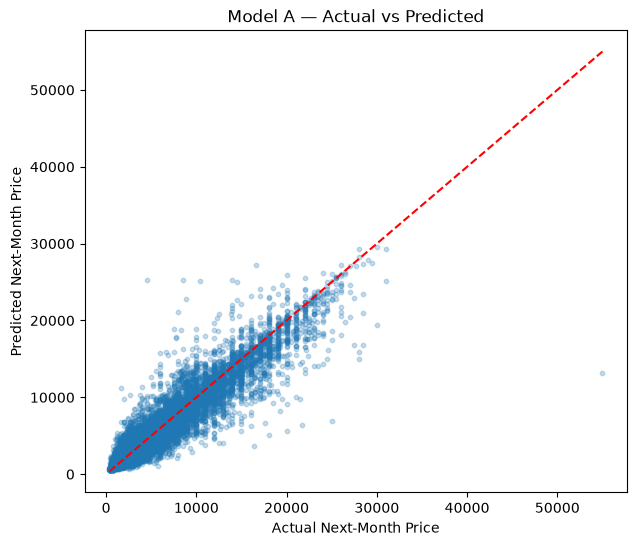

In [21]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test_a,pred_a,alpha=0.25,s=10)

min_val = min(y_test_a.min(), pred_a.min())
max_val = max(y_test_a.max(), pred_a.max())

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--", color="red")

plt.xlabel("Actual Next-Month Price")
plt.ylabel("Predicted Next-Month Price")
plt.title("Model A — Actual vs Predicted")
plt.show()

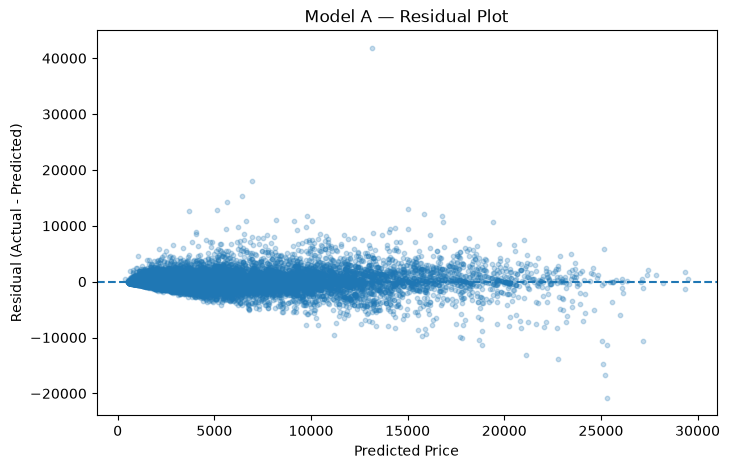

In [22]:
residuals_a = y_test_a - pred_a

plt.figure(figsize=(8, 5))

plt.scatter(
    pred_a,
    residuals_a,
    alpha=0.25,
    s=10
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Model A — Residual Plot")
plt.show()

In [23]:
print("Baseline MAE :", baseline_mae)
print("Model A MAE  :", mae_a)

print("Baseline RMSE:", baseline_rmse)
print("Model A RMSE :", rmse_a)

print("Baseline R²  :", baseline_r2)
print("Model A R²   :", r2_a)

Baseline MAE : 590.0960911528862
Model A MAE  : 606.7573354243594
Baseline RMSE: 1149.699735716894
Model A RMSE : 1110.382712794025
Baseline R²  : 0.9027194284603602
Model A R²   : 0.9092591937030644


In [24]:
train_commodities = set(train_df["Commodity"].unique())
test_commodities = set(test_df["Commodity"].unique())

print("Common commodities:", sorted(train_commodities & test_commodities))
print("Only in train:", sorted(train_commodities - test_commodities))
print("Only in test:", sorted(test_commodities - train_commodities))

Common commodities: ['Apples', 'Cabbage', 'Carrot', 'Cauliflower', 'Chilli', 'Cucumber', 'Garlic', 'Grapes', 'Guava', 'Mango', 'Onion', 'Orange', 'Papaya', 'Peas', 'Pineapples', 'Pomegranate', 'Potato', 'Tomato']
Only in train: []
Only in test: []


In [25]:
print("Train varieties:", train_df["Variety"].nunique())
print("Test varieties :", test_df["Variety"].nunique())

train_varieties = set(train_df["Variety"].dropna().unique())
test_varieties = set(test_df["Variety"].dropna().unique())

print("Common varieties:", len(train_varieties & test_varieties))
print("Test-only varieties:", sorted(test_varieties - train_varieties))

Train varieties: 91
Test varieties : 86
Common varieties: 79
Test-only varieties: ['Cucumber-Organic', 'Guava Allahabad', 'Keshar', 'Kufri Giriraj', 'Kullu Delicious', 'Organic', 'Red Nanital']


In [26]:
train_varieties = set(
    train_df["Variety"].dropna().unique()
)

test_df = test_df.copy()

test_df["Variety_Seen_In_Train"] = (
    test_df["Variety"].isin(train_varieties)
)

print(
    test_df["Variety_Seen_In_Train"].value_counts()
)

Variety_Seen_In_Train
True     37398
False      264
Name: count, dtype: int64


In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

numeric_features_b = [
    "Median_Price_Per_MT",
    "Monthly_Min_Price",
    "Monthly_Max_Price",
    "Monthly_Price_Std",
    "Price_Record_Count",
    "Market_Count",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_4",
    "Price_Month"
]

categorical_features_b = [
    "Commodity",
    "Variety"
]

In [28]:
preprocessor_b = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features_b),
        ("categorical", OneHotEncoder(drop="first",handle_unknown="ignore"), categorical_features_b)])

In [29]:
model_b = Pipeline(
    steps=[
        ("preprocessor", preprocessor_b),
        ("regressor", LinearRegression())
    ]
)

In [30]:
X_train_b = train_df[
    numeric_features_b + categorical_features_b
]

X_test_b = test_df[
    numeric_features_b + categorical_features_b
]

y_train_b = train_df["Next_Month_Price"]
y_test_b = test_df["Next_Month_Price"]

model_b.fit(
    X_train_b,
    y_train_b
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Median_Price_Per_MT','Monthly_Min_Price','Monthly_Max_Price',..., 'Price_Month','Commodity','Variety']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be aut

In [31]:
pred_b = model_b.predict(X_test_b)

C:\Users\Vedant Agarwal\Desktop\Cold Storage Investment Intelligence\ColdIQ_Streamlit\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [32]:
mae_b = mean_absolute_error(y_test_b,pred_b)
rmse_b = np.sqrt(mean_squared_error(y_test_b,pred_b))
r2_b = r2_score(y_test_b,pred_b)

n = len(y_test_b)
p_b = model_b.named_steps["preprocessor"].transform(X_test_b).shape[1]

adjusted_r2_b = 1 - ((1 - r2_b) * (n - 1) / (n - p_b - 1))

print("Model B - Linear Regression")
print(f"MAE         : ₹{mae_b:,.2f}")
print(f"RMSE        : ₹{rmse_b:,.2f}")
print(f"R²          : {r2_b:.4f}")
print(f"Adjusted R² : {adjusted_r2_b:.4f}")

Model B - Linear Regression
MAE         : ₹602.41
RMSE        : ₹1,104.84
R²          : 0.9102
Adjusted R² : 0.9099


C:\Users\Vedant Agarwal\Desktop\Cold Storage Investment Intelligence\ColdIQ_Streamlit\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [33]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Model A - Price History", "Model B - + Commodity/Variety"],
    "MAE": [baseline_mae, mae_a, mae_b],
    "RMSE": [baseline_rmse, rmse_a, rmse_b],
    "R2": [baseline_r2, r2_a, r2_b]
})

comparison

,Model,MAE,RMSE,R2
0,Baseline,590.096091,1149.699736,0.902719
1,Model A - Price History,606.757335,1110.382713,0.909259
2,Model B - + Commodity/Variety,602.409476,1104.836373,0.910163


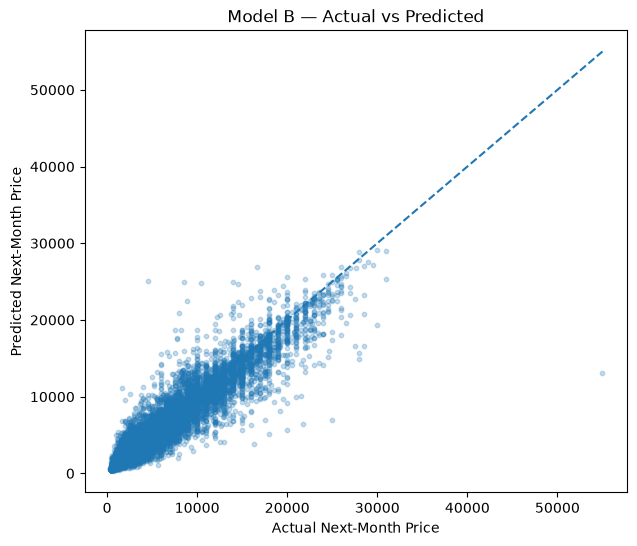

In [34]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test_b,
    pred_b,
    alpha=0.25,
    s=10
)

min_val = min(
    y_test_b.min(),
    pred_b.min()
)

max_val = max(
    y_test_b.max(),
    pred_b.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Next-Month Price")
plt.ylabel("Predicted Next-Month Price")
plt.title("Model B — Actual vs Predicted")
plt.show()

In [35]:
train_varieties = set(train_df["Variety"].dropna().unique())

seen_mask = test_df["Variety"].isin(train_varieties)

print("Seen variety rows  :", seen_mask.sum())
print("Unseen variety rows:", (~seen_mask).sum())

mae_seen = mean_absolute_error(y_test_b[seen_mask], pred_b[seen_mask])
mae_unseen = mean_absolute_error(y_test_b[~seen_mask], pred_b[~seen_mask])

print("MAE - Seen varieties   :", mae_seen)
print("MAE - Unseen varieties :", mae_unseen)

Seen variety rows  : 37398
Unseen variety rows: 264
MAE - Seen varieties   : 604.3226945081718
MAE - Unseen varieties : 331.38461504747505


In [36]:
from sklearn.metrics import mean_absolute_percentage_error

baseline_mape = mean_absolute_percentage_error(y_test, baseline_predictions) * 100
model_a_mape = mean_absolute_percentage_error(y_test_a, pred_a) * 100
model_b_mape = mean_absolute_percentage_error(y_test_b, pred_b) * 100

print("Baseline MAPE :", baseline_mape)
print("Model A MAPE  :", model_a_mape)
print("Model B MAPE  :", model_b_mape)

Baseline MAPE : 17.24806908982898
Model A MAPE  : 18.846526821089473
Model B MAPE  : 17.93653323056967


In [37]:
numeric_features_c = [
    "Median_Price_Per_MT",
    "Monthly_Min_Price",
    "Monthly_Max_Price",
    "Monthly_Price_Std",
    "Price_Record_Count",
    "Market_Count",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_4",
    "Price_Month"
]

categorical_features_c = [
    "Commodity",
    "Variety",
    "State",
    "District"
]

In [38]:
preprocessor_c = ColumnTransformer(
    transformers=[
        ("numeric","passthrough", numeric_features_c),
        ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),categorical_features_c)])

In [39]:
model_c = Pipeline(steps=[("preprocessor", preprocessor_c), ("regressor", LinearRegression())])

In [40]:
X_train_c = train_df[numeric_features_c + categorical_features_c]
X_test_c = test_df[numeric_features_c + categorical_features_c]

y_train_c = train_df["Next_Month_Price"]
y_test_c = test_df["Next_Month_Price"]

model_c.fit(X_train_c,y_train_c)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](15,)","['Median_Price_Per_MT','Monthly_Min_Price','Monthly_Max_Price',..., 'Variety','State','District']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,15
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatica

In [41]:
pred_c = model_c.predict(X_test_c)

C:\Users\Vedant Agarwal\Desktop\Cold Storage Investment Intelligence\ColdIQ_Streamlit\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [42]:
mae_c = mean_absolute_error(y_test_c, pred_c)
rmse_c = np.sqrt(mean_squared_error(y_test_c, pred_c))
r2_c = r2_score(y_test_c, pred_c)
mape_c = mean_absolute_percentage_error(y_test_c, pred_c) * 100

print("Model C")
print("MAE :", mae_c)
print("RMSE:", rmse_c)
print("R²  :", r2_c)
print("MAPE:", mape_c)

Model C
MAE : 602.5739571913338
RMSE: 1103.5132109750411
R²  : 0.9103784761523711
MAPE: 17.944646343944488


In [43]:
comparison = pd.DataFrame({
    "Model": ["Baseline", "Model A - Price History", "Model B - A + Commodity,Variety", "Model C- B + District,State"],
    "MAE": [baseline_mae, mae_a, mae_b, mae_c],
    "RMSE": [baseline_rmse, rmse_a, rmse_b, rmse_c],
    "R2": [baseline_r2, r2_a, r2_b, r2_c],
    "MAPE":[baseline_mape, model_a_mape, model_b_mape, mape_c]
})

comparison

,Model,MAE,RMSE,R2,MAPE
0,Baseline,590.096091,1149.699736,0.902719,17.248069
1,Model A - Price History,606.757335,1110.382713,0.909259,18.846527
2,"Model B - A + Commodity,Variety",602.409476,1104.836373,0.910163,17.936533
3,"Model C- B + District,State",602.573957,1103.513211,0.910378,17.944646


In [44]:
query = """
SELECT *
FROM ml_holding_price
"""

holding_df = pd.read_sql(query, engine)

print(holding_df.shape)
holding_df.head()

(75235, 21)


,Commodity,Commodity_ID,Variety,State,District,Month_Date,Price_Year,Price_Month,Median_Price_Per_MT,Monthly_Min_Price,...,Monthly_Price_Std,Price_Record_Count,Market_Count,Price_Lag_1,Price_Lag_2,Price_Lag_3,Price_Lag_4,Holding_Months,Target_Month,Future_Selling_Price
0,Apples,1,American,Bihar,Araria,2022-02-01,2022,2,5600.0,4200.0,...,628.215197,25,1,NaN,NaN,NaN,NaN,5,2022-07-01,8900.0
1,Apples,1,American,Bihar,Kishanganj,2022-02-01,2022,2,9000.0,2500.0,...,3213.253803,5,2,NaN,NaN,NaN,NaN,6,2022-08-01,7350.0
2,Apples,1,American,Bihar,Kishanganj,2022-03-01,2022,3,8500.0,5500.0,...,1148.290655,21,2,9000.0,NaN,NaN,NaN,6,2022-09-01,7000.0
3,Apples,1,American,Bihar,Kishanganj,2022-04-01,2022,4,9200.0,7000.0,...,1063.436616,13,2,8500.0,9000.0,NaN,NaN,6,2022-10-01,6200.0
4,Apples,1,American,Bihar,Kishanganj,2022-05-01,2022,5,10000.0,4200.0,...,2622.181026,16,2,9200.0,8500.0,9000.0,NaN,6,2022-11-01,5900.0


In [45]:
holding_df["Holding_Months"].value_counts().sort_index()

Holding_Months
1      6851
2     22889
3      4838
4      4487
5      8526
6     17869
7      7359
8       661
9       739
10     1016
Name: count, dtype: int64

In [46]:
holding_df["Month_Sin"] = np.sin(
    2 * np.pi * holding_df["Price_Month"] / 12
)

holding_df["Month_Cos"] = np.cos(
    2 * np.pi * holding_df["Price_Month"] / 12
)

In [47]:
holding_df = holding_df.sort_values(
    "Month_Date"
).reset_index(drop=True)

split_date = "2025-07-01"

train_h = holding_df[
    holding_df["Month_Date"] < split_date
]

test_h = holding_df[
    holding_df["Month_Date"] >= split_date
]

print("Train:", train_h.shape)
print("Test :", test_h.shape)

Train: (64545, 23)
Test : (10690, 23)


In [48]:
baseline_h_pred = test_h["Median_Price_Per_MT"]

baseline_h_mae = mean_absolute_error(
    test_h["Future_Selling_Price"],
    baseline_h_pred
)

baseline_h_rmse = np.sqrt(
    mean_squared_error(
        test_h["Future_Selling_Price"],
        baseline_h_pred
    )
)

baseline_h_mape = mean_absolute_percentage_error(
    test_h["Future_Selling_Price"],
    baseline_h_pred
) * 100

baseline_h_r2 = r2_score(
    test_h["Future_Selling_Price"],
    baseline_h_pred
)

print("Holding-period baseline")
print("-----------------------")
print(f"MAE  : ₹{baseline_h_mae:,.2f}")
print(f"RMSE : ₹{baseline_h_rmse:,.2f}")
print(f"MAPE : {baseline_h_mape:.2f}%")
print(f"R²   : {baseline_h_r2:.4f}")

Holding-period baseline
-----------------------
MAE  : ₹1,298.75
RMSE : ₹2,286.29
MAPE : 36.43%
R²   : 0.7466


In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer

In [50]:
numeric_features = [
    "Median_Price_Per_MT",
    "Monthly_Min_Price",
    "Monthly_Max_Price",
    "Monthly_Price_Std",
    "Price_Record_Count",
    "Market_Count",
    "Price_Lag_1",
    "Price_Lag_2",
    "Price_Lag_3",
    "Price_Lag_4",
    "Month_Sin",
    "Month_Cos",
    "Holding_Months"
]

categorical_features = [
    "Commodity",
    "Variety",
    "State",
    "District"
]

In [51]:
numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

In [52]:
X_train = train_h[
    numeric_features + categorical_features
]

X_test = test_h[
    numeric_features + categorical_features
]

y_train = train_h[
    "Future_Selling_Price"
]

y_test = test_h[
    "Future_Selling_Price"
]

In [53]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

In [54]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),

        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [55]:
X_train.isna().sum().sort_values(ascending=False)

Price_Lag_4            14255
Price_Lag_3            11215
Price_Lag_2             7869
Price_Lag_1             4131
Monthly_Price_Std       1089
Median_Price_Per_MT        0
Price_Record_Count         0
Monthly_Min_Price          0
Monthly_Max_Price          0
Market_Count               0
Month_Sin                  0
Month_Cos                  0
Holding_Months             0
Commodity                  0
Variety                    0
State                      0
District                   0
dtype: int64

In [56]:
X_test.isna().sum().sort_values(ascending=False)

Price_Lag_4            2534
Price_Lag_3            2147
Price_Lag_2            1619
Price_Lag_1             915
Monthly_Price_Std       266
Median_Price_Per_MT       0
Price_Record_Count        0
Monthly_Min_Price         0
Monthly_Max_Price         0
Market_Count              0
Month_Sin                 0
Month_Cos                 0
Holding_Months            0
Commodity                 0
Variety                   0
State                     0
District                  0
dtype: int64

In [57]:
rf_model.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['Median_Price_Per_MT','Monthly_Min_Price','Monthly_Max_Price',..., 'Variety','State','District']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed t

In [58]:
rf_pred = rf_model.predict(X_test)

C:\Users\Vedant Agarwal\Desktop\Cold Storage Investment Intelligence\ColdIQ_Streamlit\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [59]:
rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_mape = mean_absolute_percentage_error(
    y_test,
    rf_pred
) * 100

rf_r2 = r2_score(
    y_test,
    rf_pred
)

print("FINAL RANDOM FOREST")
print("-------------------")
print(f"MAE  : ₹{rf_mae:,.2f}")
print(f"RMSE : ₹{rf_rmse:,.2f}")
print(f"MAPE : {rf_mape:.2f}%")
print(f"R²   : {rf_r2:.4f}")

FINAL RANDOM FOREST
-------------------
MAE  : ₹1,073.57
RMSE : ₹1,933.28
MAPE : 30.25%
R²   : 0.8188


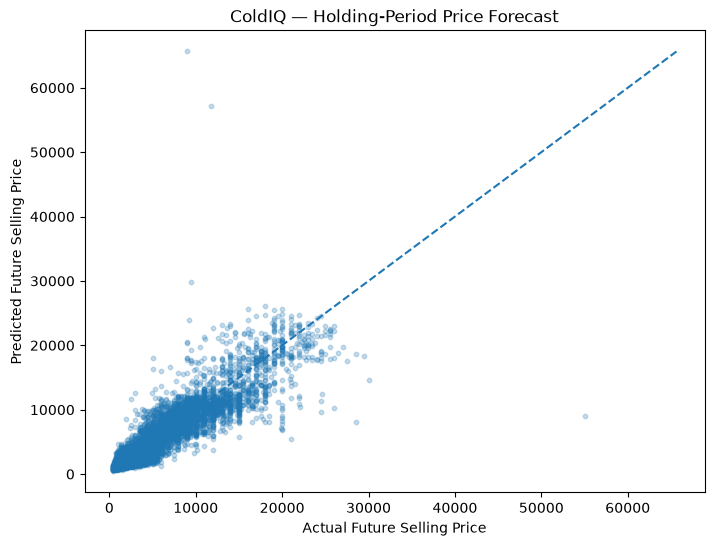

In [60]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_pred,
    alpha=0.25,
    s=10
)

min_val = min(
    y_test.min(),
    rf_pred.min()
)

max_val = max(
    y_test.max(),
    rf_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Future Selling Price")
plt.ylabel("Predicted Future Selling Price")
plt.title("ColdIQ — Holding-Period Price Forecast")
plt.show()

In [61]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_pipeline_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                add_indicator=True
            )
        )
    ]
)

# Categorical preprocessing
categorical_pipeline_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

# Combine preprocessing
preprocessor_lr = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_pipeline_lr,
            numeric_features
        ),
        (
            "cat",
            categorical_pipeline_lr,
            categorical_features
        )
    ]
)

# Linear Regression pipeline
lr_holding = Pipeline(
    steps=[
        ("preprocessor", preprocessor_lr),
        ("regressor", LinearRegression())
    ]
)

In [62]:
lr_holding.fit(
    X_train,
    y_train
)
lr_pred = lr_holding.predict(X_test)

C:\Users\Vedant Agarwal\Desktop\Cold Storage Investment Intelligence\ColdIQ_Streamlit\.venv\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 3] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [63]:
lr_mae = mean_absolute_error(
    y_test,
    lr_pred
)

lr_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        lr_pred
    )
)

lr_mape = mean_absolute_percentage_error(
    y_test,
    lr_pred
) * 100

lr_r2 = r2_score(
    y_test,
    lr_pred
)

print("HOLDING-PERIOD LINEAR REGRESSION")
print("--------------------------------")
print(f"MAE  : ₹{lr_mae:,.2f}")
print(f"RMSE : ₹{lr_rmse:,.2f}")
print(f"MAPE : {lr_mape:.2f}%")
print(f"R²   : {lr_r2:.4f}")

HOLDING-PERIOD LINEAR REGRESSION
--------------------------------
MAE  : ₹1,229.37
RMSE : ₹2,047.73
MAPE : 35.54%
R²   : 0.7967


In [64]:
holding_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Random Forest"
    ],
    "MAE": [
        baseline_h_mae,
        lr_mae,
        rf_mae
    ],
    "RMSE": [
        baseline_h_rmse,
        lr_rmse,
        rf_rmse
    ],
    "MAPE": [
        baseline_h_mape,
        lr_mape,
        rf_mape
    ],
    "R2": [
        baseline_h_r2,
        lr_r2,
        rf_r2
    ]
})

holding_comparison

,Model,MAE,RMSE,MAPE,R2
0,Persistence Baseline,1298.754983,2286.286036,36.426266,0.746572
1,Linear Regression,1229.370428,2047.731515,35.539495,0.796699
2,Random Forest,1073.568836,1933.282977,30.246460,0.818789


In [65]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for rf_weight in np.arange(0, 1.01, 0.05):

    lr_weight = 1 - rf_weight

    ensemble_pred = (
        lr_weight * lr_pred +
        rf_weight * rf_pred
    )

    mae = mean_absolute_error(y_test, ensemble_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, ensemble_pred)
    )

    mape = mean_absolute_percentage_error(
        y_test,
        ensemble_pred
    ) * 100

    r2 = r2_score(
        y_test,
        ensemble_pred
    )

    results.append({
        "RF_Weight": rf_weight,
        "LR_Weight": lr_weight,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    })

ensemble_results = pd.DataFrame(results)

ensemble_results.sort_values("MAPE").head(10)

,RF_Weight,LR_Weight,MAE,RMSE,MAPE,R2
15,0.75,0.25,1045.592718,1848.451345,29.448512,0.834343
14,0.70,0.30,1045.390789,1840.485675,29.461523,0.835768
16,0.80,0.20,1047.535343,1859.502530,29.496327,0.832357
13,0.65,0.35,1046.914098,1835.645687,29.535690,0.836631
17,0.85,0.15,1051.474535,1873.584632,29.608863,0.829808
12,0.60,0.40,1050.295074,1833.956130,29.666049,0.836931
18,0.90,0.10,1057.251099,1890.629924,29.776848,0.826697
11,0.55,0.45,1055.878276,1835.425703,29.851867,0.836670
19,0.95,0.05,1064.673805,1910.559100,29.988668,0.823024
10,0.50,0.50,1063.209787,1840.046837,30.093872,0.835846


In [81]:
import joblib
import json
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

joblib.dump(
    lr_holding,
    model_dir / "coldiq_linear_holding.pkl"
)

joblib.dump(
    rf_model,
    model_dir / "coldiq_random_forest_holding.pkl"
)

ensemble_config = {
    "linear_regression_weight": 0.30,
    "random_forest_weight": 0.70,
    "target": "Future_Selling_Price",
    "horizon_column": "Holding_Months",
    "evaluation": {
        "MAE": 1045.39,
        "RMSE": 1840.49,
        "MAPE": 29.46,
        "R2": 0.8358
    }
}

with open(
    model_dir / "ensemble_config.json",
    "w"
) as f:
    json.dump(ensemble_config, f, indent=4)

print("Models saved.")

Models saved.


In [82]:
model_schema = {
    "numeric_features": numeric_features,
    "categorical_features": categorical_features
}

with open(
    model_dir / "feature_schema.json",
    "w"
) as f:
    json.dump(model_schema, f, indent=4)

print("Schema saved.")

Schema saved.


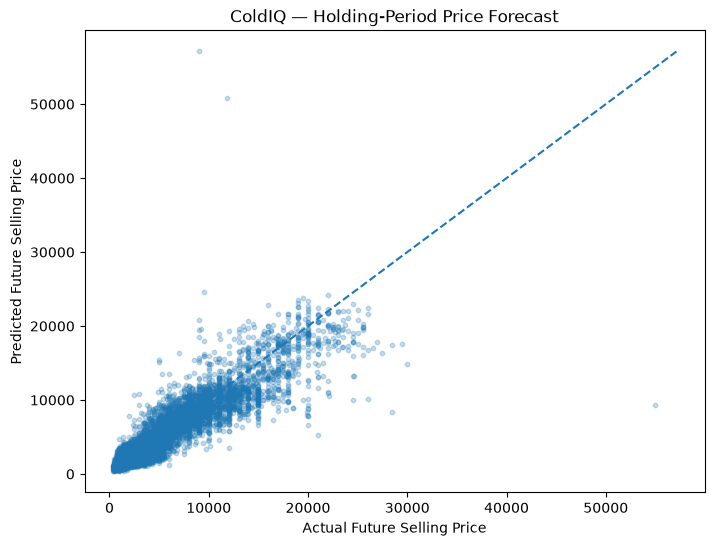

In [83]:
ensemble_pred = (
    0.30 * lr_pred +
    0.70 * rf_pred
)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    ensemble_pred,
    alpha=0.25,
    s=10
)

min_val = min(
    y_test.min(),
    ensemble_pred.min()
)

max_val = max(
    y_test.max(),
    ensemble_pred.max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Future Selling Price")
plt.ylabel("Predicted Future Selling Price")
plt.title("ColdIQ — Holding-Period Price Forecast")
plt.show()

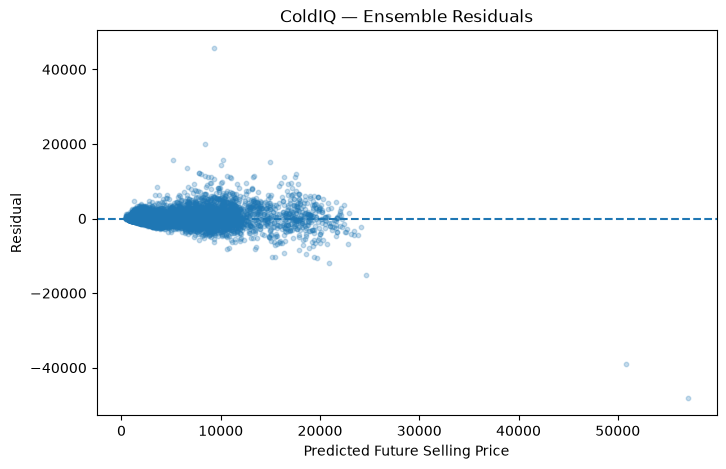

In [84]:
ensemble_residuals = y_test - ensemble_pred

plt.figure(figsize=(8, 5))

plt.scatter(
    ensemble_pred,
    ensemble_residuals,
    alpha=0.25,
    s=10
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Future Selling Price")
plt.ylabel("Residual")
plt.title("ColdIQ — Ensemble Residuals")
plt.show()